In [1]:
import copy, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42); np.random.seed(42)
torch.set_num_threads(torch.get_num_threads())   # use all CPU cores
device = torch.device("cpu")

DATA_ROOT = "./data"          # folder that contains MNIST/raw/ (change if examiner gives another path)
DATASET   = "MNIST"
EPS_LIST  = [0.05, 0.10, 0.20, 0.30]
EPS_AT    = 0.20              # epsilon for adversarial training
N_EVAL    = 2000              # test images used for attacks (speed). Set 10000 for full test set

## Load data (pixels in [0,1])

In [2]:
tf = transforms.ToTensor()
train_ds = datasets.MNIST(DATA_ROOT, train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=tf)
train_loader     = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader_full = DataLoader(test_ds, batch_size=1000, shuffle=False)
test_loader      = DataLoader(Subset(test_ds, range(N_EVAL)), batch_size=1000, shuffle=False)
print(len(train_ds), len(test_ds), "| attack evaluation on", N_EVAL, "test images")

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 402kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.78MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.21MB/s]

60000 10000 | attack evaluation on 2000 test images


## Model, attacks, helper functions

In [3]:
class CNN(nn.Module):
    # 2 conv layers + 2 fully connected layers
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 16, 3, padding=1)
        self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.f1 = nn.Linear(32*7*7, 64)
        self.f2 = nn.Linear(64, 10)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.relu(self.f1(x.flatten(1)))
        return self.f2(x)

def fgsm(model, x, y, eps):
    x = x.clone().detach().requires_grad_(True)
    g = torch.autograd.grad(F.cross_entropy(model(x), y), x)[0]
    return (x + eps*g.sign()).clamp(0, 1).detach()

def pgd(model, x, y, eps, iters=10):
    alpha = eps/4
    xa = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1).detach()   # random start
    for _ in range(iters):
        xa.requires_grad_(True)
        g = torch.autograd.grad(F.cross_entropy(model(xa), y), xa)[0]
        xa = xa.detach() + alpha*g.sign()
        xa = torch.min(torch.max(xa, x-eps), x+eps).clamp(0, 1)               # project to eps-ball
    return xa.detach()

def train(model, epochs, adv=False, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        for x, y in train_loader:
            if adv:                                   # 50:50 clean + FGSM(0.20)
                model.eval(); xa = fgsm(model, x, y, EPS_AT); model.train()
                x, y = torch.cat([x, xa]), torch.cat([y, y])
            opt.zero_grad(); F.cross_entropy(model(x), y).backward(); opt.step()
        print(f"  epoch {ep+1}/{epochs} done")
    model.eval(); return model

def accuracy(model, loader, attack=None, eps=0.0):
    model.eval(); correct = n = 0
    for x, y in loader:
        if attack is not None and eps > 0: x = attack(model, x, y, eps)
        with torch.no_grad(): correct += (model(x).argmax(1) == y).sum().item()
        n += len(y)
    return 100.0*correct/n

## Task 1 - Baseline CNN (Adam, lr=0.001, batch 64, 2 epochs)

In [4]:
t0 = time.time()
print("Training baseline CNN (2 epochs)...")
base = train(CNN().to(device), epochs=2)
clean_acc_full = accuracy(base, test_loader_full)   # full 10,000 test images
clean_acc      = accuracy(base, test_loader)        # same subset used for attacks
print(f"Clean test accuracy (full 10000): {clean_acc_full:.1f} %")
print(f"Clean accuracy on attack subset ({N_EVAL}): {clean_acc:.1f} %   [{time.time()-t0:.0f}s]")

Training baseline CNN (2 epochs)...
  epoch 1/2 done
  epoch 2/2 done
Clean test accuracy (full 10000): 98.3 %
Clean accuracy on attack subset (2000): 97.8 %   [75s]


## Task 2 & 3 - FGSM and PGD (L-inf, 10 iterations, alpha = eps/4, random start)

In [5]:
t0 = time.time()
fgsm_acc, pgd_acc = {0.0: clean_acc}, {0.0: clean_acc}
for e in EPS_LIST:
    fgsm_acc[e] = accuracy(base, test_loader, fgsm, e)
    pgd_acc[e]  = accuracy(base, test_loader, pgd,  e)

print("EPSILON  FGSM_ACC  PGD_ACC")
print("-"*31)
for e in [0.0]+EPS_LIST:
    print(f" {e:4.2f}    {fgsm_acc[e]:5.1f} %   {pgd_acc[e]:5.1f} %")
print("-"*31)
print(f"Attack success (eps=0.20): FGSM {100-fgsm_acc[EPS_AT]:.1f} %, PGD {100-pgd_acc[EPS_AT]:.1f} %   [{time.time()-t0:.0f}s]")

EPSILON  FGSM_ACC  PGD_ACC
-------------------------------
 0.00     97.8 %    97.8 %
 0.05     90.8 %    89.4 %
 0.10     76.0 %    61.4 %
 0.20     26.2 %     0.7 %
 0.30      3.2 %     0.0 %
-------------------------------
Attack success (eps=0.20): FGSM 73.8 %, PGD 99.3 %   [50s]


## Task 4 - Clean vs FGSM (eps = 0.20) digits with predicted labels

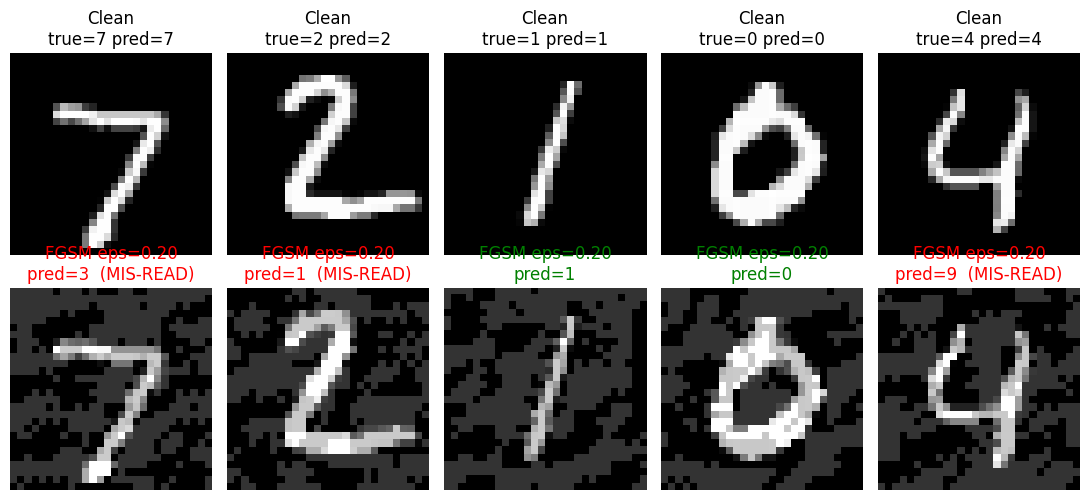

Mis-read digits (true -> predicted): ['7 -> 3', '2 -> 1', '4 -> 9']
Mis-read digits saved : clean_vs_adversarial.png


In [6]:
xs, ys = next(iter(DataLoader(test_ds, batch_size=200, shuffle=False)))
with torch.no_grad(): ok = (base(xs).argmax(1) == ys).nonzero().flatten()[:5]   # 5 correctly-read digits
xs, ys = xs[ok], ys[ok]
xadv = fgsm(base, xs, ys, EPS_AT)
with torch.no_grad(): p_clean, p_adv = base(xs).argmax(1), base(xadv).argmax(1)

fig, ax = plt.subplots(2, 5, figsize=(11, 5)); misread = []
for i in range(5):
    ax[0,i].imshow(xs[i,0], cmap="gray", vmin=0, vmax=1)
    ax[0,i].set_title(f"Clean\ntrue={ys[i].item()} pred={p_clean[i].item()}")
    ax[1,i].imshow(xadv[i,0], cmap="gray", vmin=0, vmax=1)
    wrong = p_adv[i].item() != ys[i].item()
    ax[1,i].set_title(f"FGSM eps=0.20\npred={p_adv[i].item()}" + ("  (MIS-READ)" if wrong else ""),
                      color="red" if wrong else "green")
    if wrong: misread.append(f"{ys[i].item()} -> {p_adv[i].item()}")
    ax[0,i].axis("off"); ax[1,i].axis("off")
plt.tight_layout(); plt.savefig("clean_vs_adversarial.png", dpi=150); plt.show()
print("Mis-read digits (true -> predicted):", misread if misread else "none")
print("Mis-read digits saved : clean_vs_adversarial.png")

## Task 5 - Adversarial training (2 epochs, 50:50 clean + FGSM eps=0.20)

In [7]:
t0 = time.time()
print("Adversarial fine-tuning...")
robust = train(copy.deepcopy(base), epochs=2, adv=True)
r_clean = accuracy(robust, test_loader)
r_fgsm  = accuracy(robust, test_loader, fgsm, EPS_AT)
r_pgd   = accuracy(robust, test_loader, pgd,  EPS_AT)

print("\nMODEL            CLEAN    FGSM(0.20)  PGD(0.20)")
print("-"*52)
print(f"Baseline         {clean_acc:5.1f} %   {fgsm_acc[EPS_AT]:5.1f} %     {pgd_acc[EPS_AT]:5.1f} %")
print(f"Adv. trained     {r_clean:5.1f} %   {r_fgsm:5.1f} %     {r_pgd:5.1f} %")
print("-"*52)
print(f"Clean accuracy change : {r_clean-clean_acc:+.1f} %")
print(f"FGSM robustness gain : {r_fgsm-fgsm_acc[EPS_AT]:+.1f} %   PGD gain : {r_pgd-pgd_acc[EPS_AT]:+.1f} %   [{time.time()-t0:.0f}s]")

Adversarial fine-tuning...
  epoch 1/2 done
  epoch 2/2 done

MODEL            CLEAN    FGSM(0.20)  PGD(0.20)
----------------------------------------------------
Baseline          97.8 %    26.2 %       0.7 %
Adv. trained      98.2 %    85.1 %      22.4 %
----------------------------------------------------
Clean accuracy change : +0.4 %
FGSM robustness gain : +58.9 %   PGD gain : +21.8 %   [180s]


## Task 6 - Accuracy vs epsilon (baseline)

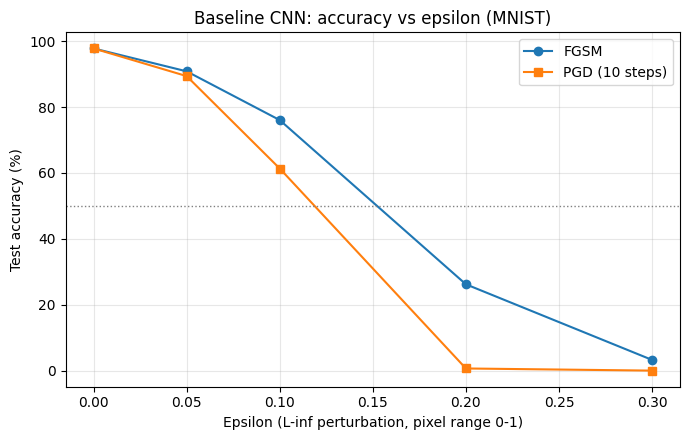

Plot saved : accuracy_vs_epsilon.png


In [8]:
es = [0.0]+EPS_LIST
plt.figure(figsize=(7,4.5))
plt.plot(es, [fgsm_acc[e] for e in es], "o-", label="FGSM")
plt.plot(es, [pgd_acc[e]  for e in es], "s-", label="PGD (10 steps)")
plt.axhline(50, color="grey", ls=":", lw=1)
plt.xlabel("Epsilon (L-inf perturbation, pixel range 0-1)"); plt.ylabel("Test accuracy (%)")
plt.title("Baseline CNN: accuracy vs epsilon (MNIST)"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150); plt.show()
print("Plot saved : accuracy_vs_epsilon.png")

## Values for Q1-Q4 (copy these into your report)

In [9]:
below = [e for e in EPS_LIST if fgsm_acc[e] < 50]
print("Q1  clean acc =", f"{clean_acc_full:.1f}%", "| FGSM:", {e: round(fgsm_acc[e],1) for e in EPS_LIST})
print("    first eps with FGSM acc < 50% :", below[0] if below else "none")
print("Q2  PGD stronger at every eps :", all(pgd_acc[e] <= fgsm_acc[e] for e in EPS_LIST))
print("    PGD:", {e: round(pgd_acc[e],1) for e in EPS_LIST})
print("Q3  mis-read digits :", misread)
print(f"    clean {clean_acc:.1f}->{r_clean:.1f} | FGSM {fgsm_acc[EPS_AT]:.1f}->{r_fgsm:.1f} | PGD {pgd_acc[EPS_AT]:.1f}->{r_pgd:.1f}")

Q1  clean acc = 98.3% | FGSM: {0.05: 90.8, 0.1: 76.0, 0.2: 26.2, 0.3: 3.2}
    first eps with FGSM acc < 50% : 0.2
Q2  PGD stronger at every eps : True
    PGD: {0.05: 89.4, 0.1: 61.4, 0.2: 0.7, 0.3: 0.0}
Q3  mis-read digits : ['7 -> 3', '2 -> 1', '4 -> 9']
    clean 97.8->98.2 | FGSM 26.2->85.1 | PGD 0.7->22.4
